## Q3.0 Linear Regression with Regularization

In [1]:
# Imports necessary libraries & Q1's Dataset.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error

df = pd.read_csv("data/df.csv")
test = pd.read_csv("data/test_df.csv")
train = pd.read_csv("data/train_df.csv")
val = pd.read_csv("data/val_df.csv")

# Generate seed based on my college ID.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)

# Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="rocket", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    plt.text(0.95, -0.1, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.tight_layout()
    plt.show()

def coordplot(ax, title, x_label, y_label):
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

Seed generated: 1027714457


In [2]:
def run_poly_regression(X_train, y_train, X_val, y_val, X_test, y_test,
                        degree=1, regularizer=None, reg_strength=0.1):

    # Create & Scale Polynomial Features.
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_val_poly = poly.transform(X_val)
    X_test_poly = poly.transform(X_test)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_poly)
    X_val_scaled = scaler.transform(X_val_poly)
    X_test_scaled = scaler.transform(X_test_poly)

    # Select and Initialize the Model.
    if regularizer == 'l1':
        model = Lasso(alpha=reg_strength, max_iter=10000, random_state=seed)
    elif regularizer == 'l2':
        model = Ridge(alpha=reg_strength, random_state=seed)
    else:
        model = LinearRegression()

    model.fit(X_train_scaled, y_train)

    y_pred_train = model.predict(X_train_scaled)
    y_pred_val = model.predict(X_val_scaled)
    y_pred_test = model.predict(X_test_scaled)

    # Calculates MSE.
    mse_train = mean_squared_error(y_train, y_pred_train)
    mse_val = mean_squared_error(y_val, y_pred_val)
    mse_test = mean_squared_error(y_test, y_pred_test)

    results = {'train_mse': mse_train, 'val_mse': mse_val,
        'test_mse': mse_test, 'coefficients': model.coef_,
        'poly_features': poly, 'scaler': scaler, 'model': model}
    
    return results

### Fitting Polynomial Regression Models
The original dataset splits that we have saved from ***Q2.0*** must be preprocessed for the polynomial features to be constructed from the class.
The GPA Feature is dropped since it is the feature we are attempting to predict. 

In [3]:
# Drop GPA from split datasets to seperate features.
X_train = train.drop('GPA', axis=1)
y_train = train['GPA']

X_val = val.drop('GPA', axis=1)
y_val = val['GPA']

X_test = test.drop('GPA', axis=1)
y_test = test['GPA']


# Binary One-Hot Encoding, 9x1 Rspresentation. 
X_train_encoded = pd.get_dummies(X_train, columns=['Gender', 'Major', 'Program'])
X_val_encoded = pd.get_dummies(X_val, columns=['Gender', 'Major', 'Program'])
X_test_encoded = pd.get_dummies(X_test, columns=['Gender', 'Major', 'Program'])

X_val_final = X_val_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
X_test_final = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)


# Parameter Sweeps.
regularizers = [None, 'l1', 'l2']
degrees = [1, 2, 3, 4, 5, 6]
reg_strengths = [0.001, 0.01, 0.1, 1, 10.0, 100.0]

# Processing for Upcoming Questions.
results_list = []
for reg in regularizers:
    if reg is None:
        for deg in degrees:
            res = run_poly_regression(X_train_encoded, y_train, X_val_final, y_val, X_test_final, y_test,
                                      degree=deg, regularizer=None)
            results_list.append({'degree': deg, 'regularizer': 'None', 'strength': 0, **res})
    else:
        for deg in degrees:
            for strength in reg_strengths:
                res = run_poly_regression(X_train_encoded, y_train, X_val_final, y_val, X_test_final, y_test,
                                          degree=deg, regularizer=reg, reg_strength=strength)
                results_list.append({'degree': deg, 'regularizer': reg, 'strength': strength, **res})

results_df = pd.DataFrame(results_list)

# print("--- Top 10 Best Performing Models (sorted by Validation MSE) ---")
# display_cols = ['degree', 'regularizer', 'strength', 'val_mse', 'train_mse', 'test_mse']

### Polynomial Degree vs MSE

There are two main results that are observed as the degree of our polynomial increases.
- The ***Training Set MSE*** has a decreasing trend throughout the sweep.
- The ***Validation & Test Set MSEs*** begin to increase as the sweep progresses.

This indicates that the model begins to ***overfit*** as the polynomial degree increases. 


 Data for: Degree vs. MSE (No Regularization)
 degree  train_mse  val_mse  test_mse
      1   0.824921 0.802016  0.803649
      2   0.823468 0.802972  0.805829
      3   0.822877 0.802926  0.806983
      4   0.822877 0.802926  0.806983
      5   0.822877 0.802926  0.806983
      6   0.822877 0.802926  0.806983


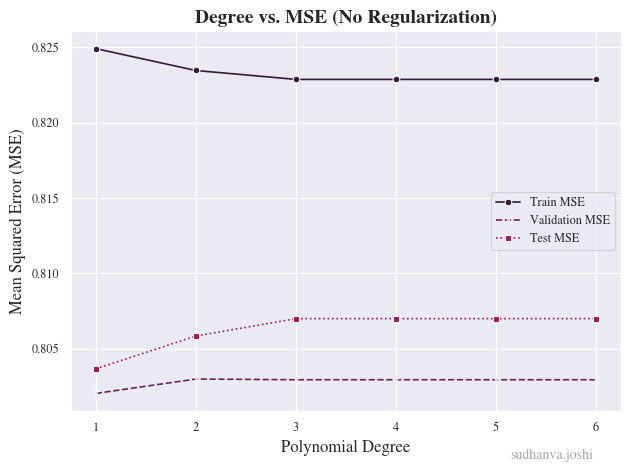


 Data for: Degree vs. MSE (L1 Regularization, Strength=0.01)
 degree  train_mse  val_mse  test_mse
      1   0.825398 0.800516  0.800749
      2   0.824350 0.801169  0.802298
      3   0.824173 0.800935  0.802388
      4   0.824173 0.800935  0.802388
      5   0.824173 0.800935  0.802388
      6   0.824173 0.800935  0.802388


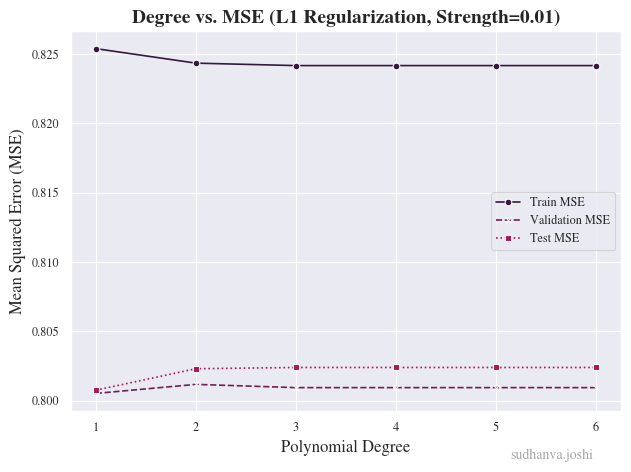


 Data for: Degree vs. MSE (L2 Regularization, Strength=0.01)
 degree  train_mse  val_mse  test_mse
      1   0.824921 0.802016  0.803649
      2   0.823468 0.802972  0.805829
      3   0.822877 0.802926  0.806983
      4   0.822877 0.802926  0.806983
      5   0.822877 0.802926  0.806983
      6   0.822877 0.802926  0.806983


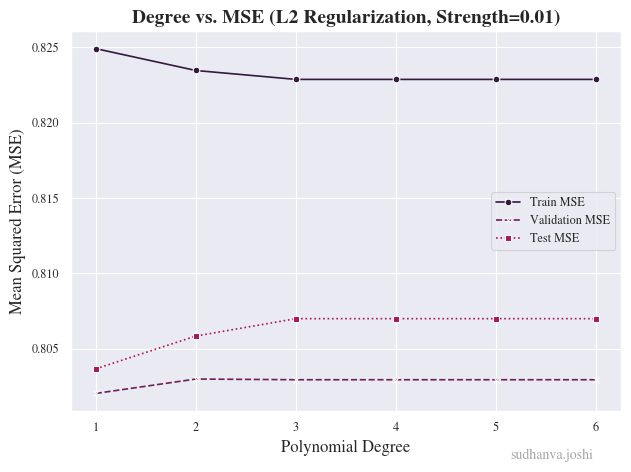

In [4]:
display_cols = ['degree', 'train_mse', 'val_mse', 'test_mse']
for reg in regularizers:
    if reg is None:
        plot_df = results_df[results_df['regularizer'] == 'None']
        title = 'Degree vs. MSE (No Regularization)'
    else:
        strength_to_plot = 0.01
        plot_df = results_df[(results_df['regularizer'] == reg) & (results_df['strength'] == strength_to_plot)]
        title = f'Degree vs. MSE ({reg.upper()} Regularization, Strength={strength_to_plot})'

    print(f"\n Data for: {title}")
    print(plot_df[display_cols].to_string(index=False))
    
    sns.lineplot(data=plot_df, x='degree', y='train_mse', marker='o', label='Train MSE')
    sns.lineplot(data=plot_df, x='degree', y='val_mse', marker='x', linestyle='--', label='Validation MSE')
    sns.lineplot(data=plot_df, x='degree', y='test_mse', marker='s', linestyle=':', label='Test MSE')
    plt.legend()
    plotinfo(title, 'Polynomial Degree', 'Mean Squared Error (MSE)')

### Optimizing Regularization Strength

It is observed that the optimal degree for each regularizer ends up being ***1***. This is due to the fact that ***One-Hot Encoding*** is being used as the encoding scheme for our features. Raising the polynomial degree becomes irrelevant in this case, as: $$ x^{n} = x $$

Hence, overfitting simply considers noise in the dataset, worsening performance as a result.

It is seen that L2 seems to have no effect on the MSE of our runs, as it follows the same trends as all baseline MSEs in various strength runs. This is because most features are uncorrelated to predicting GPA *(with the exception of Major)* which causes the Ridge selection to not act strongly upon the existing equations.

Additionally, L1 MSE worsens drastically as the regularization strength is increased due to the absolute error terms becoming dominant in the loss function. This shows that the model will ***underfit*** if we crank $\lambda$ too high.


 Data for: Degree vs. MSE (L2 Regularization, Strength=0.01)

Baseline (No Regularization):
regularizer  degree  val_mse
       None       1 0.802016
       None       2 0.802972
       None       3 0.802926
       None       4 0.802926
       None       5 0.802926
       None       6 0.802926

L1 Regularization:
regularizer  degree  val_mse
         l1       1 0.801825
         l1       2 0.802781
         l1       3 0.802542
         l1       4 0.802542
         l1       5 0.802542
         l1       6 0.802543

L2 Regularization:
regularizer  degree  val_mse
         l2       1 0.802016
         l2       2 0.802972
         l2       3 0.802926
         l2       4 0.802926
         l2       5 0.802926
         l2       6 0.802926


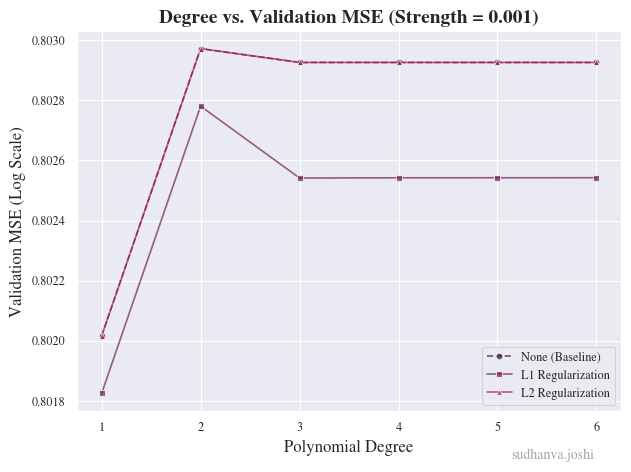


 Data for: Degree vs. MSE (L2 Regularization, Strength=0.01)

Baseline (No Regularization):
regularizer  degree  val_mse
       None       1 0.802016
       None       2 0.802972
       None       3 0.802926
       None       4 0.802926
       None       5 0.802926
       None       6 0.802926

L1 Regularization:
regularizer  degree  val_mse
         l1       1 0.800516
         l1       2 0.801169
         l1       3 0.800935
         l1       4 0.800935
         l1       5 0.800935
         l1       6 0.800935

L2 Regularization:
regularizer  degree  val_mse
         l2       1 0.802016
         l2       2 0.802972
         l2       3 0.802926
         l2       4 0.802926
         l2       5 0.802926
         l2       6 0.802926


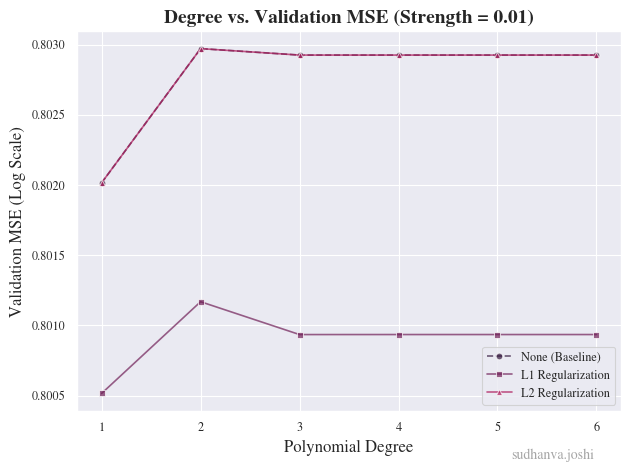


 Data for: Degree vs. MSE (L2 Regularization, Strength=0.01)

Baseline (No Regularization):
regularizer  degree  val_mse
       None       1 0.802016
       None       2 0.802972
       None       3 0.802926
       None       4 0.802926
       None       5 0.802926
       None       6 0.802926

L1 Regularization:
regularizer  degree  val_mse
         l1       1 0.813242
         l1       2 0.813242
         l1       3 0.813242
         l1       4 0.813242
         l1       5 0.813242
         l1       6 0.813242

L2 Regularization:
regularizer  degree  val_mse
         l2       1 0.802016
         l2       2 0.802972
         l2       3 0.802926
         l2       4 0.802926
         l2       5 0.802926
         l2       6 0.802926


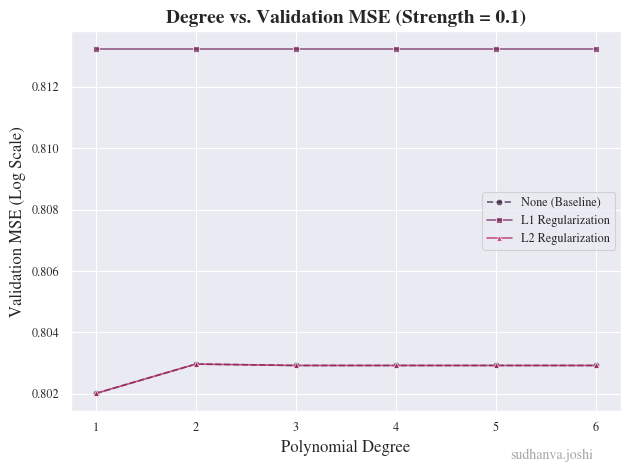


 Data for: Degree vs. MSE (L2 Regularization, Strength=0.01)

Baseline (No Regularization):
regularizer  degree  val_mse
       None       1 0.802016
       None       2 0.802972
       None       3 0.802926
       None       4 0.802926
       None       5 0.802926
       None       6 0.802926

L1 Regularization:
regularizer  degree  val_mse
         l1       1 1.065229
         l1       2 1.065229
         l1       3 1.065229
         l1       4 1.065229
         l1       5 1.065229
         l1       6 1.065229

L2 Regularization:
regularizer  degree  val_mse
         l2       1 0.802016
         l2       2 0.802972
         l2       3 0.802926
         l2       4 0.802926
         l2       5 0.802926
         l2       6 0.802926


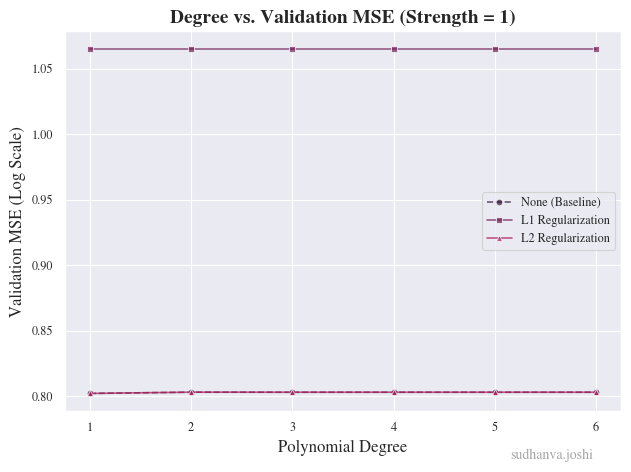


 Data for: Degree vs. MSE (L2 Regularization, Strength=0.01)

Baseline (No Regularization):
regularizer  degree  val_mse
       None       1 0.802016
       None       2 0.802972
       None       3 0.802926
       None       4 0.802926
       None       5 0.802926
       None       6 0.802926

L1 Regularization:
regularizer  degree  val_mse
         l1       1 1.065229
         l1       2 1.065229
         l1       3 1.065229
         l1       4 1.065229
         l1       5 1.065229
         l1       6 1.065229

L2 Regularization:
regularizer  degree  val_mse
         l2       1 0.802015
         l2       2 0.802967
         l2       3 0.802925
         l2       4 0.802926
         l2       5 0.802926
         l2       6 0.802926


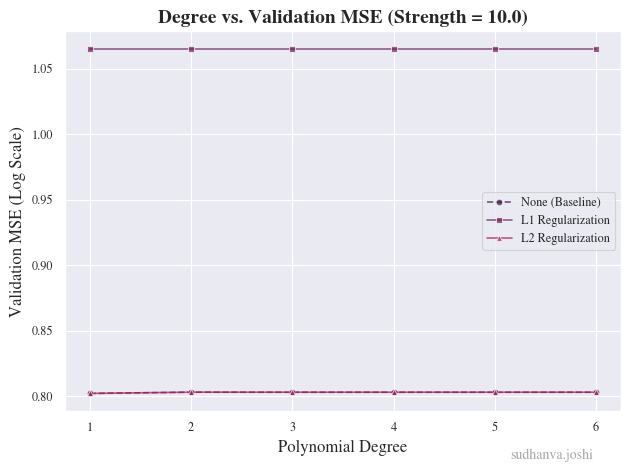


 Data for: Degree vs. MSE (L2 Regularization, Strength=0.01)

Baseline (No Regularization):
regularizer  degree  val_mse
       None       1 0.802016
       None       2 0.802972
       None       3 0.802926
       None       4 0.802926
       None       5 0.802926
       None       6 0.802926

L1 Regularization:
regularizer  degree  val_mse
         l1       1 1.065229
         l1       2 1.065229
         l1       3 1.065229
         l1       4 1.065229
         l1       5 1.065229
         l1       6 1.065229

L2 Regularization:
regularizer  degree  val_mse
         l2       1 0.802026
         l2       2 0.802926
         l2       3 0.802911
         l2       4 0.802922
         l2       5 0.802924
         l2       6 0.802925


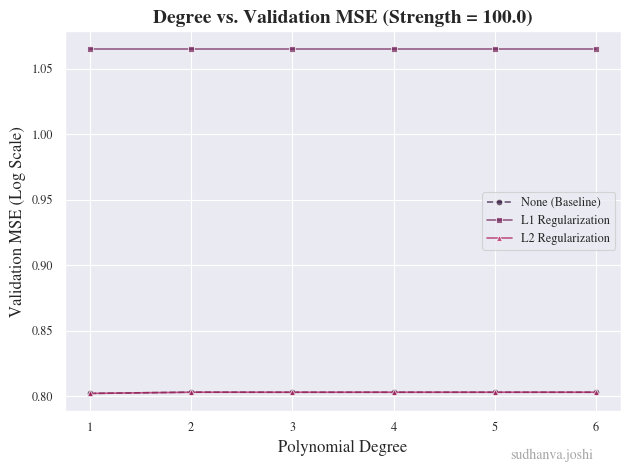

In [5]:
display_cols = ['regularizer', 'degree', 'val_mse']
baseline_df = results_df[results_df['regularizer'] == 'None']

for strength in reg_strengths:
    l1_df_strength = results_df[(results_df['regularizer'] == 'l1') & (results_df['strength'] == strength)]
    l2_df_strength = results_df[(results_df['regularizer'] == 'l2') & (results_df['strength'] == strength)]

    print(f"\n Data for: {title}")
    print("\nBaseline (No Regularization):")
    print(baseline_df[display_cols].to_string(index=False))
    print("\nL1 Regularization:")
    print(l1_df_strength[display_cols].to_string(index=False))
    print("\nL2 Regularization:")
    print(l2_df_strength[display_cols].to_string(index=False))
    
    sns.lineplot(data=baseline_df, x='degree', y='val_mse', marker='o', alpha = 0.7,
                 linestyle='--', label='None (Baseline)')
    sns.lineplot(data=l1_df_strength, x='degree', y='val_mse', marker='s', alpha = 0.7,
                 label='L1 Regularization')
    sns.lineplot(data=l2_df_strength, x='degree', y='val_mse', marker='^', alpha = 0.7,
                 label='L2 Regularization')
    
    plotinfo(title=f'Degree vs. Validation MSE (Strength = {strength})',
             x='Polynomial Degree', y='Validation MSE (Log Scale)')

### Regularization Strength (log scale) vs Val MSE, Best Degree


 Data for: Strength vs. Validation MSE for Degree 1 (No Regularization)
Baseline MSE (constant): 0.802016


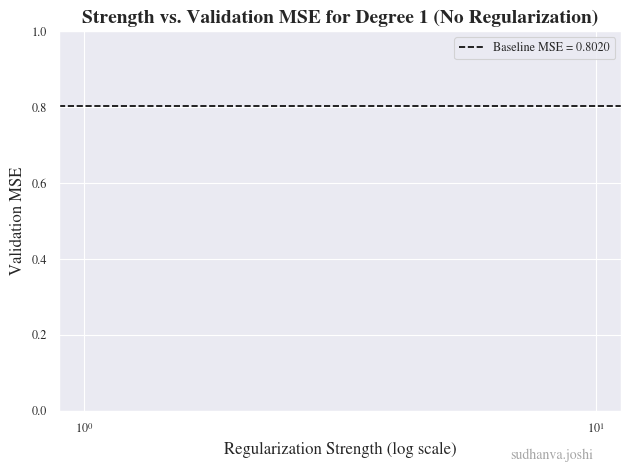


 Data for: Strength vs. Validation MSE for Degree 1 (L1 Regularization)
 strength  val_mse
    0.001 0.801825
    0.010 0.800516
    0.100 0.813242
    1.000 1.065229
   10.000 1.065229
  100.000 1.065229


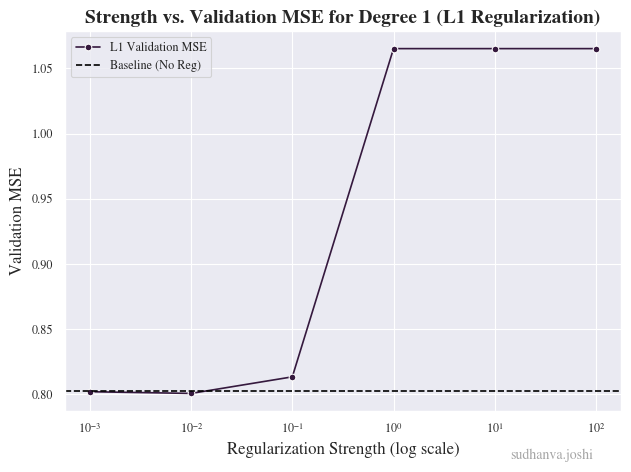


 Data for: Strength vs. Validation MSE for Degree 1 (L2 Regularization)
 strength  val_mse
    0.001 0.802016
    0.010 0.802016
    0.100 0.802016
    1.000 0.802016
   10.000 0.802015
  100.000 0.802026


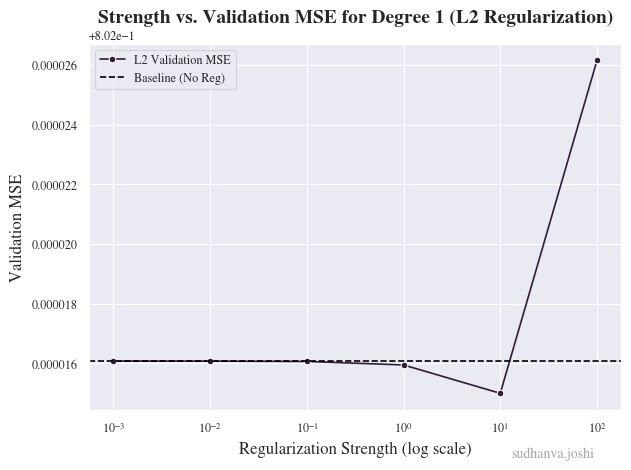

In [6]:
display_cols = ['strength', 'val_mse']
baseline_mse = results_df[(results_df['regularizer'] == 'None') & (results_df['degree'] == 1)]['val_mse'].iloc[0]

for reg in regularizers:
    if reg is None:
        title = 'Strength vs. Validation MSE for Degree 1 (No Regularization)'
        
        print(f"\n Data for: {title}")
        print(f"Baseline MSE (constant): {baseline_mse:.6f}")
        
        plt.axhline(y=baseline_mse, color='k', linestyle='--', label=f'Baseline MSE = {baseline_mse:.4f}')

    else:
        title = f'Strength vs. Validation MSE for Degree 1 ({reg.upper()} Regularization)'
        plot_df = results_df[(results_df['regularizer'] == reg) & (results_df['degree'] == 1)]
        
        print(f"\n Data for: {title}")
        print(plot_df[display_cols].to_string(index=False))
        
        sns.lineplot(data=plot_df, x='strength', y='val_mse', marker='o', label=f'{reg.upper()} Validation MSE')
        plt.axhline(y=baseline_mse, color='k', linestyle='--', label='Baseline (No Reg)')

    plt.xscale('log')
    plt.legend()
    plt.ticklabel_format(style='plain', axis='y')
    plotinfo(title, 'Regularization Strength (log scale)', 'Validation MSE')

### Performance Improvements

The best setup for least MSE is:
$$
L1\;Regularization,\;Strength = 0.01,\;Degree = 1
$$
This improves the loss from *0.802016* to *0.8005*.

### Feature Weights
In both regularization setups, it is observed that **Major** is the most pertinent feature in predicting GPA. This is due to the fact that our GPA distributions were conditioned on Major, hence making it the most important feature.

The relevant features that remain in both regularization setups are tabulated below.

**L1 Observations:** Since the feature coefficients tend to be reduced to 0, we end up with few non-zero weighted features. 

**L2 Observations:** Since the feature coefficients tend to be shrunk to smaller absolute values, seemingly uncorrelated features also contribute to our loss function through their weights. 

In [7]:
best_l1_model_row = results_df.loc[results_df[results_df['regularizer'] == 'l1']['val_mse'].idxmin()]
best_l2_model_row = results_df.loc[results_df[results_df['regularizer'] == 'l2']['val_mse'].idxmin()]

print("Best L1 Model (Lasso)")
print(best_l1_model_row[['degree', 'strength', 'val_mse']])
print("\nBest L2 Model (Ridge)")
print(best_l2_model_row[['degree', 'strength', 'val_mse']])

l1_model = best_l1_model_row['model']
l1_poly = best_l1_model_row['poly_features']
l1_feature_names = l1_poly.get_feature_names_out(X_train_encoded.columns)
l1_coeffs = pd.Series(l1_model.coef_, index=l1_feature_names)

print("\nL1 (Lasso) Important Predictors for GPA")
print("Features with non-zero weights, sorted by importance:")
print(l1_coeffs.sort_values(key=abs, ascending=False).head(10))


# Extract the fitted model and polynomial feature objects
l2_model = best_l2_model_row['model']
l2_poly = best_l2_model_row['poly_features']
l2_feature_names = l2_poly.get_feature_names_out(X_train_encoded.columns)
l2_coeffs = pd.Series(l2_model.coef_, index=l2_feature_names)

print("\nL2 (Ridge) Important Predictors for GPA")
print("Top 10 features, sorted by importance:")
print(l2_coeffs.sort_values(key=abs, ascending=False).head(10))

Best L1 Model (Lasso)
degree             1
strength        0.01
val_mse     0.800516
Name: 7, dtype: object

Best L2 Model (Ridge)
degree             1
strength        10.0
val_mse     0.802015
Name: 46, dtype: object

L1 (Lasso) Important Predictors for GPA
Features with non-zero weights, sorted by importance:
Major_B.Tech    -0.448436
Major_PhD        0.079191
Program_CHD      0.034815
Gender_Other     0.012953
Gender_Male      0.000000
Gender_Female   -0.000000
Major_MS         0.000000
Program_CND     -0.000000
Program_CSE      0.000000
Program_ECE     -0.000000
dtype: float64

L2 (Ridge) Important Predictors for GPA
Top 10 features, sorted by importance:
Major_B.Tech    -0.273567
Major_PhD        0.204155
Major_MS         0.159485
Program_CHD      0.036111
Gender_Other     0.022281
Program_CND     -0.015530
Program_ECE     -0.008696
Gender_Female   -0.007465
Program_CSE     -0.006264
Gender_Male      0.000972
dtype: float64
